# 08. Evaluación y comparación de modelos

Este notebook evalúa **una sola vez** la versión 2 de los cuatro modelos congelados `07_*_v2` en la semana de prueba (2013-04-24 a 2013-04-30). Los modelos se reentrenaron con entrenamiento y validación hasta el 23 de abril, conservando las configuraciones y los umbrales seleccionados previamente; aquí no se vuelve a ajustar ningún modelo congelado.

Además, mide la generalización a ofertas no vistas mediante cinco divisiones `GroupShuffleSplit`. Esos modelos son temporales: se descartan al finalizar cada división.

## Preparación

El notebook funciona al ejecutarse desde la raíz del proyecto o desde `notebooks/`. Las llamadas a `src/evaluacion.py` usan su API pública (`evaluar_modelo_congelado`, `metricas_binarias`, `curva_roc` y `validar_por_ofertas`); las firmas se documentan con `inspect.signature` para hacer visible cualquier cambio de contrato.

In [1]:
from pathlib import Path
import inspect
import json
import os
import platform
import sys

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from sklearn.model_selection import GroupShuffleSplit

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'src').exists():
    ROOT_DIR = ROOT_DIR.parent
if not (ROOT_DIR / 'src').exists():
    raise RuntimeError('Ejecute desde la raíz del proyecto o desde notebooks/.')
if str(ROOT_DIR / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT_DIR / 'src'))

from config import FIGURES_DIR, MODELS_DIR, TABLES_DIR
from evaluacion import curva_roc, evaluar_modelo_congelado, metricas_binarias, validar_por_ofertas
from modelo import columnas_numericas_modelo, crear_pipeline_modelo, dividir_en_tres_conjuntos
from modelos_congelados import cargar_modelos
from preprocesamiento import cargar_dataset_modelo

for carpeta in (FIGURES_DIR, TABLES_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE, GRIS = '#0072B2', '#D55E00', '#009E73', '#999999'
COLORES = [AZUL, '#E69F00', VERDE, '#CC79A7']  # paleta cualitativa Okabe-Ito
FECHA_CORTE = pd.Timestamp.today().date().isoformat()

def estilo(ax, titulo, xlabel=None, ylabel=None):
    ax.set_title(titulo, loc='left', fontsize=13)
    ax.set_xlabel(xlabel or '')
    ax.set_ylabel(ylabel or '')
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.grid(True, color='#E5E5EC', linewidth=0.8)
    ax.set_axisbelow(True)

def pie(fig, texto='dataset_modelo.csv; evaluación reproducible'):
    fig.text(0.01, 0.01, f'Fuente: {texto}. Fecha de ejecución: {FECHA_CORTE}.', color='#777777', fontsize=8)

print('Firmas de la biblioteca de evaluación:')
for funcion in (metricas_binarias, curva_roc, evaluar_modelo_congelado, validar_por_ofertas):
    print(f'- {funcion.__name__}{inspect.signature(funcion)}')

Firmas de la biblioteca de evaluación:
- metricas_binarias(y_real: 'Sequence[int] | pd.Series | np.ndarray', probabilidades: 'Sequence[float] | pd.Series | np.ndarray', umbral: 'float' = 0.5) -> 'dict[str, float | int]'
- curva_roc(y_real: 'Sequence[int] | pd.Series | np.ndarray', probabilidades: 'Sequence[float] | pd.Series | np.ndarray') -> 'pd.DataFrame'
- evaluar_modelo_congelado(nombre: 'str', modelo: 'Any', datos: 'pd.DataFrame', y_real: 'str | Sequence[int] | pd.Series | np.ndarray' = 'repeater', umbral: 'float | None' = None) -> 'dict[str, Any]'
- validar_por_ofertas(datos: 'pd.DataFrame', algoritmos: 'Iterable[str] | Mapping[str, Any]', factory: 'Callable[[str, pd.DataFrame], Any]', *, columna_grupo: 'str' = 'offer', columna_objetivo: 'str' = 'repeater', n_splits: 'int' = 5, splits: 'Iterable[tuple[Sequence[int], Sequence[int]]] | None' = None, umbral: 'float' = 0.5) -> 'pd.DataFrame'


## Entorno y manifiesto de modelos

La carga se bloquea si alguna versión actual no coincide **exactamente** con la ficha `07_*`. Esta comprobación deliberadamente antecede a `joblib.load`, porque deserializar un modelo con dependencias incompatibles puede producir resultados no comparables.

In [2]:
NOMBRES_MODELOS = [
    '07_regresion_logistica_v2', '07_random_forest_v2',
    '07_gradient_boosting_v2', '07_perceptron_multicapa_v2',
]
RUTA_MANIFIESTO = MODELS_DIR / 'manifiesto.json'
with RUTA_MANIFIESTO.open(encoding='utf-8') as archivo:
    manifiesto = json.load(archivo)
FICHAS = {nombre: manifiesto['modelos'][nombre] for nombre in NOMBRES_MODELOS}

modelos_v2_en_manifiesto = [n for n, f in manifiesto['modelos'].items() if f.get('version') == 2]
if set(modelos_v2_en_manifiesto) != set(NOMBRES_MODELOS):
    raise AssertionError(f'Se esperaban exactamente cuatro fichas de versión 2; se hallaron {modelos_v2_en_manifiesto}')

versiones_actuales = {
    'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
    'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
    'joblib': joblib.__version__,
}
versiones_requeridas = FICHAS[NOMBRES_MODELOS[0]]['versiones']
for nombre, ficha in FICHAS.items():
    if ficha['versiones'] != versiones_requeridas:
        raise AssertionError(f'{nombre} no comparte las versiones del manifiesto 07_')
paquetes_estrictos = ('scikit-learn', 'numpy', 'pandas', 'scipy', 'joblib')
diferencias = {p: (versiones_requeridas[p], versiones_actuales[p]) for p in paquetes_estrictos if versiones_requeridas[p] != versiones_actuales[p]}
if diferencias:
    raise RuntimeError(f'Entorno incompatible con el manifiesto; no se cargarán joblib. Diferencias: {diferencias}')
python_requerido = versiones_requeridas['python'].split('.')[:2]
python_actual = versiones_actuales['python'].split('.')[:2]
python_compatible = python_actual == python_requerido or (python_requerido == ['3', '12'] and python_actual == ['3', '13'])
if not python_compatible:
    raise RuntimeError(f"Python incompatible: manifiesto {versiones_requeridas['python']}; actual {versiones_actuales['python']}")
if versiones_actuales['python'] != versiones_requeridas['python']:
    print(f"Advertencia: Python {versiones_actuales['python']} difiere del manifiesto {versiones_requeridas['python']}; se permite 3.13 sobre 3.12 tras comprobar la deserialización.")
pd.DataFrame([versiones_requeridas, versiones_actuales], index=['manifiesto', 'actual'])

Advertencia: Python 3.13.2 difiere del manifiesto 3.12.4; se permite 3.13 sobre 3.12 tras comprobar la deserialización.


,python,scikit-learn,numpy,pandas,scipy,joblib
manifiesto,3.12.4,1.6.1,2.1.2,2.2.3,1.15.1,1.4.2
actual,3.13.2,1.6.1,2.1.2,2.2.3,1.15.1,1.4.2


## Datos y separación temporal

La semana de prueba permanece totalmente aislada de cualquier ajuste y de la validación agrupada por oferta.

In [3]:
dataset = cargar_dataset_modelo()
division = dividir_en_tres_conjuntos(dataset)
train, validacion, prueba = division.entrenamiento, division.validacion, division.prueba

if prueba['offerdate'].min() != pd.Timestamp('2013-04-24') or prueba['offerdate'].max() != pd.Timestamp('2013-04-30'):
    raise AssertionError('La semana de prueba debe ser exactamente 2013-04-24 a 2013-04-30.')
if set(prueba.index).intersection(train.index) or set(prueba.index).intersection(validacion.index):
    raise AssertionError('La prueba no puede traslaparse con ajuste o validación.')

pd.DataFrame([
    {'conjunto': n, 'filas': len(d), 'inicio': d['offerdate'].min().date(), 'fin': d['offerdate'].max().date(), 'tasa_recompra': d['repeater'].mean()}
    for n, d in [('entrenamiento', train), ('validación', validacion), ('prueba', prueba)]
])

,conjunto,filas,inicio,fin,tasa_recompra
0,entrenamiento,106062,2013-03-01,2013-04-16,0.230771
1,validación,18496,2013-04-17,2013-04-23,0.335965
2,prueba,35499,2013-04-24,2013-04-30,0.359109


## Evaluación única de los modelos congelados

La tabla contractual usa el umbral que fue seleccionado en validación y quedó registrado en el manifiesto. Se mide el tiempo de predicción en esta semana, mientras que el tiempo de entrenamiento reportado es el registrado al congelar cada modelo. Una oferta cuenta como vista si aparece en el entrenamiento o en la validación, porque los modelos v2 se entrenaron con ambos bloques, del 1 de marzo al 23 de abril.

In [4]:
modelos = cargar_modelos(version=2, estricto=True)
if set(modelos) != set(NOMBRES_MODELOS):
    raise AssertionError(f'La carga estricta debe devolver solo {NOMBRES_MODELOS}; devolvió {list(modelos)}')

# Los modelos v2 entrenaron con entrenamiento y validación, hasta el 23 de abril.
ofertas_vistas = set(pd.concat([train, validacion])['offer'])
mascara_oferta_vista = prueba['offer'].isin(ofertas_vistas).to_numpy()
if not mascara_oferta_vista.any() or mascara_oferta_vista.all():
    raise AssertionError('La prueba debe contener ofertas vistas y no vistas durante el entrenamiento.')

filas_metricas, probabilidades = [], {}
for nombre in NOMBRES_MODELOS:
    resultado = evaluar_modelo_congelado(
        nombre, modelos[nombre], prueba, y_real='repeater', umbral=FICHAS[nombre]['umbral']
    )
    probabilidades[nombre] = np.asarray(resultado.pop('probabilidades'), dtype=float)
    auc_vistas = metricas_binarias(prueba.loc[mascara_oferta_vista, 'repeater'], probabilidades[nombre][mascara_oferta_vista])['auc']
    auc_no_vistas = metricas_binarias(prueba.loc[~mascara_oferta_vista, 'repeater'], probabilidades[nombre][~mascara_oferta_vista])['auc']
    resultado['auc_ofertas_vistas'] = auc_vistas
    resultado['auc_ofertas_no_vistas'] = auc_no_vistas
    resultado['degradacion_auc_no_vistas'] = auc_no_vistas - auc_vistas
    resultado.pop('clasificaciones', None)
    filas_metricas.append(resultado)

metricas_prueba = pd.DataFrame(filas_metricas).sort_values('auc', ascending=False).reset_index(drop=True)
columnas_metricas = [
    'modelo', 'algoritmo', 'auc', 'precision', 'sensibilidad', 'f1', 'tn', 'fp', 'fn', 'tp',
    'umbral', 'auc_ofertas_vistas', 'auc_ofertas_no_vistas', 'degradacion_auc_no_vistas',
    'tiempo_entrenamiento_s', 'tiempo_prediccion_s',
]
metricas_prueba = metricas_prueba[[c for c in columnas_metricas if c in metricas_prueba.columns]]
metricas_prueba.to_csv(TABLES_DIR / '08_metricas_prueba.csv', index=False)

predicciones_prueba = prueba[['id', 'offer', 'repeater']].reset_index(drop=True).copy()
predicciones_prueba['oferta_vista_entrenamiento'] = mascara_oferta_vista
for nombre, valores in probabilidades.items():
    nombre_base = nombre.removeprefix('07_').removesuffix('_v2')
    predicciones_prueba[f"probabilidad_{nombre_base}"] = valores
if len(predicciones_prueba) != len(prueba) or predicciones_prueba.isna().any().any():
    raise AssertionError('Predicciones incompletas o con faltantes.')
predicciones_prueba.to_parquet(TABLES_DIR / '08_predicciones_prueba.parquet', index=False)
metricas_prueba

C:\Users\anna2\Desktop\UVG\Data Science\Proyecto-02-Data-Science\venv\fernando-eval\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\anna2\Desktop\UVG\Data Science\Proyecto-02-Data-Science\venv\fernando-eval\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1038, in __init__


,modelo,algoritmo,auc,precision,sensibilidad,f1,tn,fp,fn,tp,umbral,auc_ofertas_vistas,auc_ofertas_no_vistas,degradacion_auc_no_vistas,tiempo_entrenamiento_s,tiempo_prediccion_s
0,07_regresion_logistica_v2,regresion_logistica,0.647020,0.393600,0.884766,0.544827,5374,17377,1469,11279,0.521148,0.658948,0.642053,-0.016895,10.021710,0.114707
1,07_perceptron_multicapa_v2,perceptron_multicapa,0.646143,0.415421,0.747647,0.534084,9339,13412,3217,9531,0.268167,0.661072,0.641290,-0.019781,10.689979,0.131883
2,07_random_forest_v2,random_forest,0.615147,0.376391,0.816912,0.515340,5497,17254,2334,10414,0.201799,0.686081,0.609950,-0.076131,53.736461,0.321654
3,07_gradient_boosting_v2,gradient_boosting,0.612117,0.384558,0.762237,0.511206,7200,15551,3031,9717,0.460378,0.671693,0.607580,-0.064113,0.695822,0.070854


## Generalización a ofertas no vistas

Se generan cinco divisiones `GroupShuffleSplit` reproducibles por `offer`, usando solamente entrenamiento+validación. En cada división se crea un pipeline nuevo con los hiperparámetros de la ficha 07; ningún modelo congelado se modifica. La función de evaluación comprueba que no haya ofertas en común entre ambos lados.

In [5]:
ajuste = pd.concat([train, validacion], ignore_index=True)
separador = GroupShuffleSplit(n_splits=5, test_size=0.20, random_state=42)
splits_ofertas = list(separador.split(ajuste, ajuste['repeater'], groups=ajuste['offer']))

def parametros_pipeline(ficha):
    parametros = dict(ficha['hiperparametros'])
    if 'hidden_layer_sizes' in parametros:
        parametros['hidden_layer_sizes'] = tuple(parametros['hidden_layer_sizes'])
    return parametros

def fabrica_temporal(nombre, entrenamiento):
    ficha = FICHAS[nombre]
    return crear_pipeline_modelo(
        ficha['algoritmo'], columnas_numericas_modelo(entrenamiento), **parametros_pipeline(ficha)
    )

validacion_ofertas = validar_por_ofertas(
    ajuste, NOMBRES_MODELOS, fabrica_temporal, columna_grupo='offer',
    columna_objetivo='repeater', n_splits=5, splits=splits_ofertas,
)
if len(validacion_ofertas) != 5 * len(NOMBRES_MODELOS):
    raise AssertionError('Se esperaba una fila por algoritmo y por cada una de las cinco divisiones.')
if not validacion_ofertas['grupos_disjuntos'].all():
    raise AssertionError('Se detectaron ofertas compartidas entre entrenamiento y prueba.')
validacion_ofertas.to_csv(TABLES_DIR / '08_validacion_por_ofertas.csv', index=False)
validacion_ofertas.groupby('algoritmo')['auc'].agg(['mean', 'std', 'count']).sort_values('mean', ascending=False)

,mean,std,count
algoritmo,,,
07_gradient_boosting_v2,0.619688,0.065899,5
07_random_forest_v2,0.610715,0.034932,5
07_regresion_logistica_v2,0.608990,0.051836,5
07_perceptron_multicapa_v2,0.582374,0.058971,5


## Figuras de comparación

Las cinco figuras usan la paleta accesible Okabe-Ito, unidades explícitas, fuente y fecha. Los intervalos/barras de error de las figuras comparativas reflejan la desviación estándar de los cinco `GroupShuffleSplit`; describen variación entre ofertas, no un intervalo de confianza poblacional.

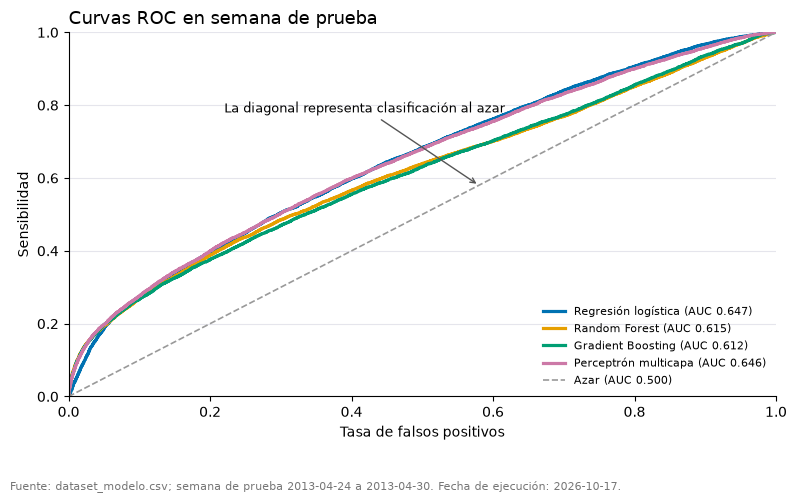

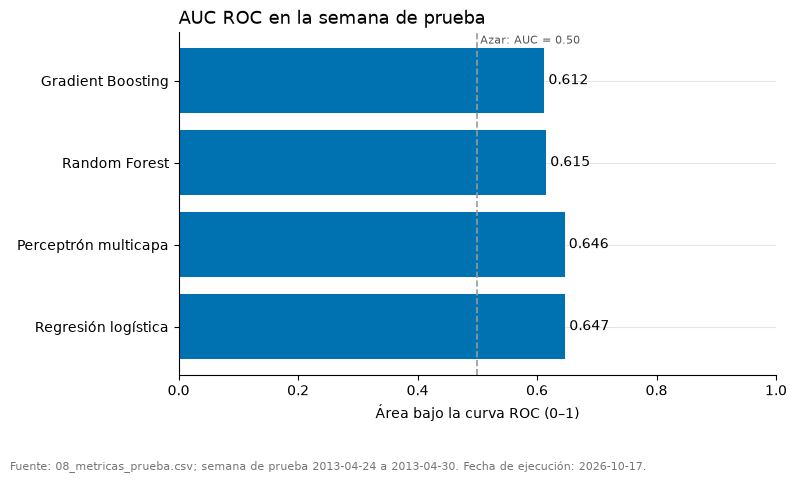

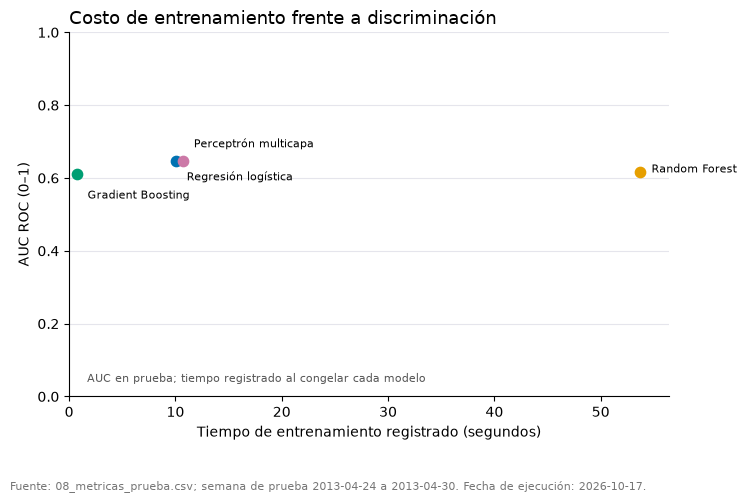

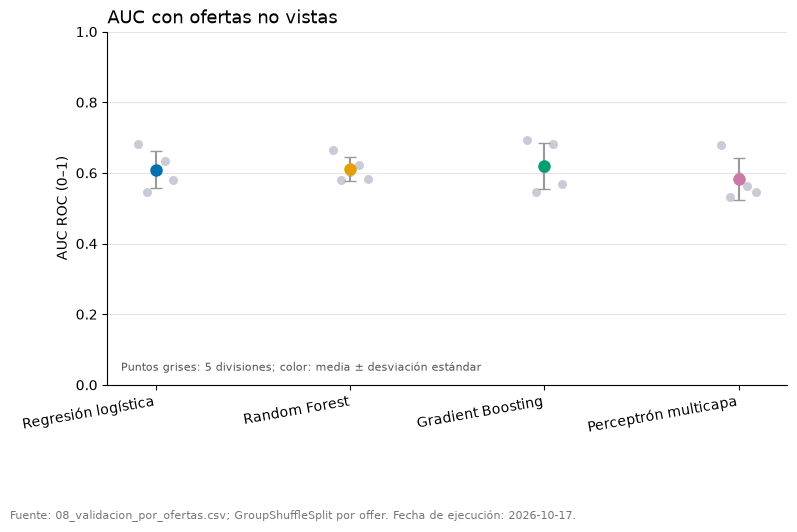

In [6]:
etiquetas = {
    '07_regresion_logistica_v2': 'Regresión logística',
    '07_random_forest_v2': 'Random Forest',
    '07_gradient_boosting_v2': 'Gradient Boosting',
    '07_perceptron_multicapa_v2': 'Perceptrón multicapa',
}
orden_auc = metricas_prueba.sort_values('auc', ascending=False)['modelo'].tolist()
resumen_ofertas = validacion_ofertas.groupby('algoritmo')['auc'].agg(media='mean', desviacion='std').reindex(NOMBRES_MODELOS)

# Pregunta: ¿qué tan bien discrimina cada modelo en la semana de prueba?
fig, ax = plt.subplots(figsize=(8, 5))
for color, nombre in zip(COLORES, NOMBRES_MODELOS):
    roc = curva_roc(prueba['repeater'], probabilidades[nombre])
    ax.plot(roc['fpr'], roc['tpr'], color=color, lw=2.3, label=f"{etiquetas[nombre]} (AUC {metricas_prueba.set_index('modelo').loc[nombre, 'auc']:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, lw=1.2, ls='--', label='Azar (AUC 0.500)')
estilo(ax, 'Curvas ROC en semana de prueba', 'Tasa de falsos positivos', 'Sensibilidad')
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.annotate('La diagonal representa clasificación al azar', xy=(0.58, 0.58), xytext=(0.22, 0.78), arrowprops={'arrowstyle': '->', 'color': '#555555'}, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
pie(fig, 'dataset_modelo.csv; semana de prueba 2013-04-24 a 2013-04-30')
fig.savefig(FIGURES_DIR / '08_curvas_roc.png', dpi=180, bbox_inches='tight')
plt.show()

# Pregunta: ¿qué AUC temporal obtiene cada modelo en la semana de prueba?
fig, ax = plt.subplots(figsize=(8, 4.8))
valores = metricas_prueba.set_index('modelo').loc[orden_auc, 'auc']
barras = ax.barh([etiquetas[n] for n in orden_auc], valores, color=AZUL)
ax.bar_label(barras, labels=[f'{v:.3f}' for v in valores], padding=3)
estilo(ax, 'AUC ROC en la semana de prueba', 'Área bajo la curva ROC (0–1)')
ax.set_xlim(0, 1)
ax.axvline(0.5, color=GRIS, lw=1.2, ls='--')
ax.annotate('Azar: AUC = 0.50', xy=(0.505, len(orden_auc) - 0.55), fontsize=8, color='#555555')
fig.tight_layout(rect=(0, 0.08, 1, 1))
pie(fig, '08_metricas_prueba.csv; semana de prueba 2013-04-24 a 2013-04-30')
fig.savefig(FIGURES_DIR / '08_auc_modelos.png', dpi=180, bbox_inches='tight')
plt.show()

# Pregunta: ¿qué compromiso hay entre tiempo de predicción y AUC?
fig, ax = plt.subplots(figsize=(7.5, 5))
tabla_tiempo = metricas_prueba.set_index('modelo').loc[NOMBRES_MODELOS]
offsets_etiquetas = {
    '07_gradient_boosting_v2': (8, -18), '07_regresion_logistica_v2': (8, -14),
    '07_perceptron_multicapa_v2': (8, 10), '07_random_forest_v2': (8, 0),
}
for color, nombre in zip(COLORES, NOMBRES_MODELOS):
    x, y = tabla_tiempo.loc[nombre, ['tiempo_entrenamiento_s', 'auc']]
    ax.scatter(x, y, color=color, s=55, zorder=3)
    ax.annotate(etiquetas[nombre], (x, y), xytext=offsets_etiquetas[nombre], textcoords='offset points', fontsize=8)
estilo(ax, 'Costo de entrenamiento frente a discriminación', 'Tiempo de entrenamiento registrado (segundos)', 'AUC ROC (0–1)')
ax.set_xlim(left=0); ax.set_ylim(0, 1)
ax.annotate('AUC en prueba; tiempo registrado al congelar cada modelo', xy=(0.03, 0.04), xycoords='axes fraction', fontsize=8, color='#555555')
fig.tight_layout(rect=(0, 0.08, 1, 1))
pie(fig, '08_metricas_prueba.csv; semana de prueba 2013-04-24 a 2013-04-30')
fig.savefig(FIGURES_DIR / '08_tiempo_vs_auc.png', dpi=180, bbox_inches='tight')
plt.show()

# Pregunta: ¿cómo cambia el AUC al reservar ofertas completas no vistas?
fig, ax = plt.subplots(figsize=(8, 5.3))
for posicion, nombre in enumerate(NOMBRES_MODELOS):
    serie = validacion_ofertas.loc[validacion_ofertas['algoritmo'] == nombre, 'auc']
    desplazamiento = np.linspace(-0.09, 0.09, len(serie))
    ax.scatter(np.full(len(serie), posicion) + desplazamiento, serie, color='#C9CCD6', s=30, zorder=2)
    ax.errorbar(posicion, serie.mean(), yerr=serie.std(), fmt='o', color=COLORES[posicion], ecolor=GRIS, capsize=4, ms=8, zorder=3)
ax.set_xticks(range(len(NOMBRES_MODELOS)), [etiquetas[n] for n in NOMBRES_MODELOS], rotation=10, ha='right')
estilo(ax, 'AUC con ofertas no vistas', ylabel='AUC ROC (0–1)')
ax.set_ylim(0, 1)
ax.annotate('Puntos grises: 5 divisiones; color: media ± desviación estándar', xy=(0.02, 0.04), xycoords='axes fraction', fontsize=8, color='#555555')
fig.tight_layout(rect=(0, 0.14, 1, 1))
pie(fig, '08_validacion_por_ofertas.csv; GroupShuffleSplit por offer')
fig.savefig(FIGURES_DIR / '08_auc_ofertas_no_vistas.png', dpi=180, bbox_inches='tight')
plt.show()

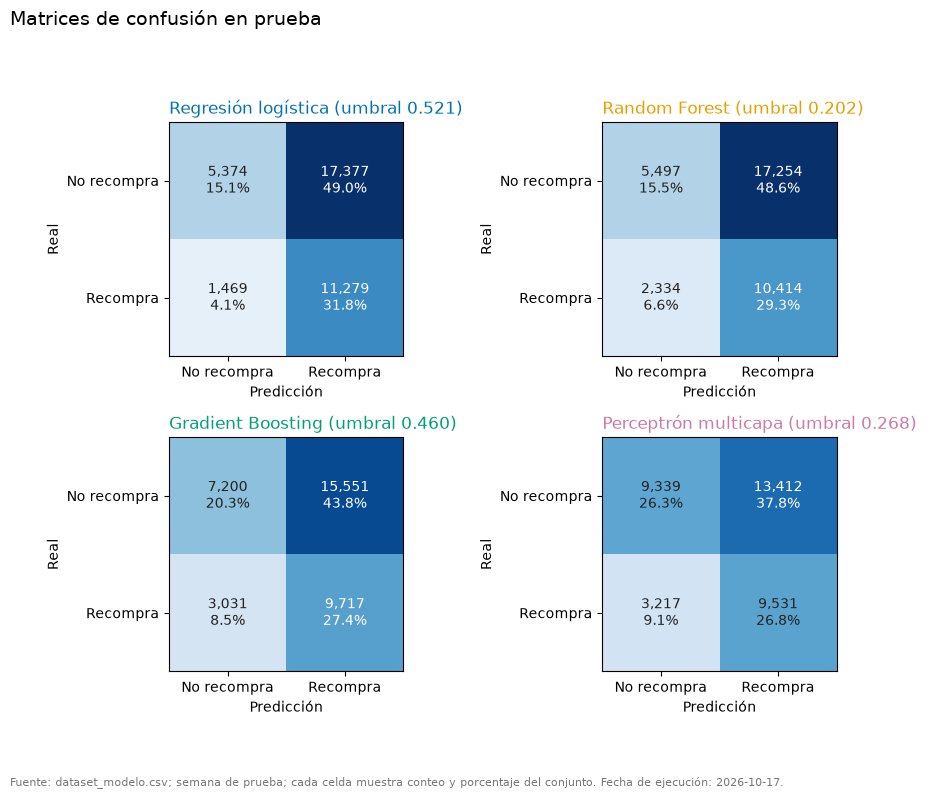

In [7]:
# Pregunta: ¿qué tipo de errores produce cada modelo con el umbral elegido en validación?
fig, ejes = plt.subplots(2, 2, figsize=(9, 8))
matrices = {nombre: metricas_binarias(prueba['repeater'], probabilidades[nombre], umbral=FICHAS[nombre]['umbral']) for nombre in NOMBRES_MODELOS}
maximo = max(max(m['tn'], m['fp'], m['fn'], m['tp']) for m in matrices.values())
for ax, nombre in zip(ejes.flat, NOMBRES_MODELOS):
    m = matrices[nombre]
    matriz = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]])
    ax.imshow(matriz, cmap='Blues', vmin=0, vmax=maximo)
    for (fila, col), valor in np.ndenumerate(matriz):
        ax.text(col, fila, f'{valor:,}\n{valor / len(prueba):.1%}', ha='center', va='center', color='white' if valor > maximo * .55 else '#222222')
    ax.set_xticks([0, 1], ['No recompra', 'Recompra'])
    ax.set_yticks([0, 1], ['No recompra', 'Recompra'])
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')
    ax.set_title(f"{etiquetas[nombre]} (umbral {FICHAS[nombre]['umbral']:.3f})", loc='left', color=COLORES[NOMBRES_MODELOS.index(nombre)], fontsize=12)
fig.suptitle('Matrices de confusión en prueba', x=0.01, ha='left', fontsize=14)
fig.tight_layout(rect=(0, 0.08, 1, 0.93))
pie(fig, 'dataset_modelo.csv; semana de prueba; cada celda muestra conteo y porcentaje del conjunto')
fig.savefig(FIGURES_DIR / '08_matrices_confusion.png', dpi=180, bbox_inches='tight')
plt.show()

## Comprobación de artefactos

Esta celda verifica los contratos de salida sin recalcular modelos. Tanto las matrices como `08_metricas_prueba.csv` usan el umbral de validación registrado para cada modelo.

In [8]:
rutas = [
    TABLES_DIR / '08_metricas_prueba.csv',
    TABLES_DIR / '08_predicciones_prueba.parquet',
    TABLES_DIR / '08_validacion_por_ofertas.csv',
    *(FIGURES_DIR / n for n in [
        '08_curvas_roc.png', '08_auc_modelos.png', '08_tiempo_vs_auc.png',
        '08_auc_ofertas_no_vistas.png', '08_matrices_confusion.png',
    ]),
]
faltantes = [str(r) for r in rutas if not r.exists() or r.stat().st_size == 0]
if faltantes:
    raise AssertionError(f'Artefactos faltantes o vacíos: {faltantes}')

esperadas = {'id', 'offer', 'repeater', 'oferta_vista_entrenamiento', *(f"probabilidad_{n.removeprefix('07_').removesuffix('_v2')}" for n in NOMBRES_MODELOS)}
if set(predicciones_prueba.columns) != esperadas:
    raise AssertionError(f'Esquema de predicciones inválido: {predicciones_prueba.columns.tolist()}')
if set(metricas_prueba['modelo']) != set(NOMBRES_MODELOS):
    raise AssertionError('Faltan métricas de algún modelo congelado.')
print('Artefactos contractuales y figuras 08 verificados.')

Artefactos contractuales y figuras 08 verificados.
